# Evidence-Aware and Uncertainty-Aware Safety Gating for Automated Alternative Credit Decisions

This notebook implements and evaluates Phase 8 of the research project: Evidence-Aware and Uncertainty-Aware Safety Gating.
It evaluates deterministic, interpretable safety rules that integrate evidence integrity (Phase 5), Out-of-Distribution covariate shift detection (Phase 6), and bootstrap predictive variance (Phase 7) into an auditable gating pipeline.

## Purpose And Boundaries

The safety gate acts as an auditable guardian preceding automated alternative credit decisions. It does not alter candidate risk probabilities, refit models, or make financial stress predictions of its own.

Its deterministic hierarchy enforces:
- **BLOCKED**: Severe evidence integrity defects (consistency contradictions, zero observed months, 100% unverified records, 100% missing required fields).
- **REVIEW_REQUIRED**: Softer evidence defects (missing months, missing fields, stale records, partially unverified records), Out-of-Distribution covariate shift (Shrinkage Mahalanobis distance $\ge 5.459$), or high predictive uncertainty ($\text{Var}(\hat{p}) \ge \tau_{\text{unc}}$).
- **SAFE_TO_AUTOMATE**: Clean, in-distribution, low-uncertainty applications.
- **Critical Policy Invariant**: Out-of-Distribution shift and high predictive uncertainty alone **never** cause an application to be BLOCKED; they strictly trigger human underwriter review.

In [1]:
import sys
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
OUTPUT_DIR = PROJECT_ROOT / "experiments" / "safety_gate"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

from src.models.safety_gate import (
    BLOCKED,
    GATE_VERSION,
    OOD_THRESHOLD,
    REVIEW_REQUIRED,
    SAFE_TO_AUTOMATE,
    UNCERTAINTY_THRESHOLDS,
    CandidatePrediction,
    EvidenceQualityInput,
    OODInput,
    UncertaintyInput,
    decide,
)
from src.data.gate_scenarios import apply_safety_gate, build_gate_panel
from src.evaluation.gate_metrics import (
    compare_experiments,
    compute_risk_coverage_curve,
    evaluate_gate,
)

sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120
print(f"Safety gate version: {GATE_VERSION}")
print(f"OOD Mahalanobis threshold: {OOD_THRESHOLD:.4f}")
print(f"Uncertainty thresholds: {UNCERTAINTY_THRESHOLDS}")

Safety gate version: phase8_hierarchical_v1
OOD Mahalanobis threshold: 5.4591
Uncertainty thresholds: {'logistic_regression': 0.000956288247270191, 'hist_gradient_boosting': 0.01628725348136607}


## 1. Construct Matched Test Panels

We construct matched panels across the 1,500 held-out test split applicants covering clean reference profiles, Phase 5 evidence degradation (12 scenario/severity pairs), Phase 6 OOD distribution shifts (3 scenarios $\times$ 3 severities), and combined interaction cohorts.

In [2]:
panel = build_gate_panel(
    model_dataset_path=PROJECT_ROOT / "data/processed/synthetic/model_dataset.csv",
    split_ids_path=PROJECT_ROOT / "experiments/ood/split_applicant_ids.csv",
    evidence_quality_path=PROJECT_ROOT / "experiments/evidence_quality/applicant_evidence_quality.csv",
    ood_scores_path=PROJECT_ROOT / "experiments/ood/ood_scores.csv",
    uncertainty_scores_path=PROJECT_ROOT / "experiments/uncertainty/uncertainty_scores.csv",
    panel_type="all",
)

print(f"Master panel shape: {panel.shape}")
print("\nCohort distribution across experiment groups:")
display(panel["experiment_group"].value_counts().to_frame("Row Count"))
print("\nSample records (verifying absence of leakage columns):")
display(panel[["applicant_id", "model_family", "scenario_label", "experiment_group", "ood_score", "predictive_variance", "financial_stress_event"]].head())

Master panel shape: (75064, 18)

Cohort distribution across experiment groups:
                   Row Count
experiment_group            
combined               33798
ood_shifted            27000
evidence_degraded      11266
clean                   3000

Sample records (verifying absence of leakage columns):
   applicant_id  ... financial_stress_event
0             3  ...                      1
1             3  ...                      1
2             7  ...                      0
3             7  ...                      0
4             8  ...                      0

[5 rows x 7 columns]


## 2. Run the Five Core Gate Experiments

We evaluate five gating regimes across both model families (`logistic_regression` and `hist_gradient_boosting`):
1. **Ungated Baseline**: Raw model predictions on clean test data with no gate intervention (100% automated).
2. **Evidence-Only Gate**: Evaluates gating on evidence quality defects only (neutralizing OOD and uncertainty).
3. **OOD-Only Gate**: Evaluates gating on covariate shift only (neutralizing evidence defects and uncertainty).
4. **Uncertainty-Only Gate**: Evaluates gating on bootstrap predictive variance only on clean test data.
5. **Full Hierarchical Gate**: Multi-signal hierarchical gating integrating all safety signals across clean, degraded, shifted, and combined panels.

In [3]:
results = []

# Experiment 1: Ungated Baseline (Clean test split)
clean_sub = panel[panel["experiment_group"] == "clean"]
g1 = apply_safety_gate(clean_sub, experiment_id="exp1_ungated", gate_mode="ungated")
for mf in ("logistic_regression", "hist_gradient_boosting"):
    results.append(evaluate_gate(g1, model_family=mf, experiment_name="1_ungated_baseline"))

# Experiment 2: Evidence-Only Gate (Clean + Defective evidence)
ev_sub = panel[panel["experiment_group"].isin(["clean", "evidence_degraded"])]
g2 = apply_safety_gate(ev_sub, experiment_id="exp2_evidence_only", gate_mode="evidence_only")
for mf in ("logistic_regression", "hist_gradient_boosting"):
    results.append(evaluate_gate(g2, model_family=mf, experiment_name="2_evidence_only"))

# Experiment 3: OOD-Only Gate (Clean + Controlled OOD shifts)
ood_sub = panel[panel["experiment_group"].isin(["clean", "ood_shifted"])]
g3 = apply_safety_gate(ood_sub, experiment_id="exp3_ood_only", gate_mode="ood_only")
for mf in ("logistic_regression", "hist_gradient_boosting"):
    results.append(evaluate_gate(g3, model_family=mf, experiment_name="3_ood_only"))

# Experiment 4: Uncertainty-Only Gate (Clean test split)
unc_sub = panel[panel["experiment_group"] == "clean"]
g4 = apply_safety_gate(unc_sub, experiment_id="exp4_uncertainty_only", gate_mode="uncertainty_only")
for mf in ("logistic_regression", "hist_gradient_boosting"):
    results.append(evaluate_gate(g4, model_family=mf, experiment_name="4_uncertainty_only"))

# Experiment 5: Full Hierarchical Gate (Full panel with all cohorts)
g5 = apply_safety_gate(panel, experiment_id="exp5_full_hierarchical", gate_mode="full")
for mf in ("logistic_regression", "hist_gradient_boosting"):
    results.append(evaluate_gate(g5, model_family=mf, experiment_name="5_full_hierarchical"))

comparison_df = compare_experiments(results)
display(comparison_df)

       experiment_name  ... accuracy_on_automated
0   1_ungated_baseline  ...              0.690667
1   1_ungated_baseline  ...              0.678667
2      2_evidence_only  ...              0.690667
3      2_evidence_only  ...              0.678667
4           3_ood_only  ...              0.690878
5           3_ood_only  ...              0.676936
6   4_uncertainty_only  ...              0.689437
7   4_uncertainty_only  ...              0.683989
8  5_full_hierarchical  ...              0.690509
9  5_full_hierarchical  ...              0.678857

[10 rows x 12 columns]


## 3. Automation Coverage, Review, and Block Rates

We visualize how each gate configuration trades off automation coverage against human review and application blocking.

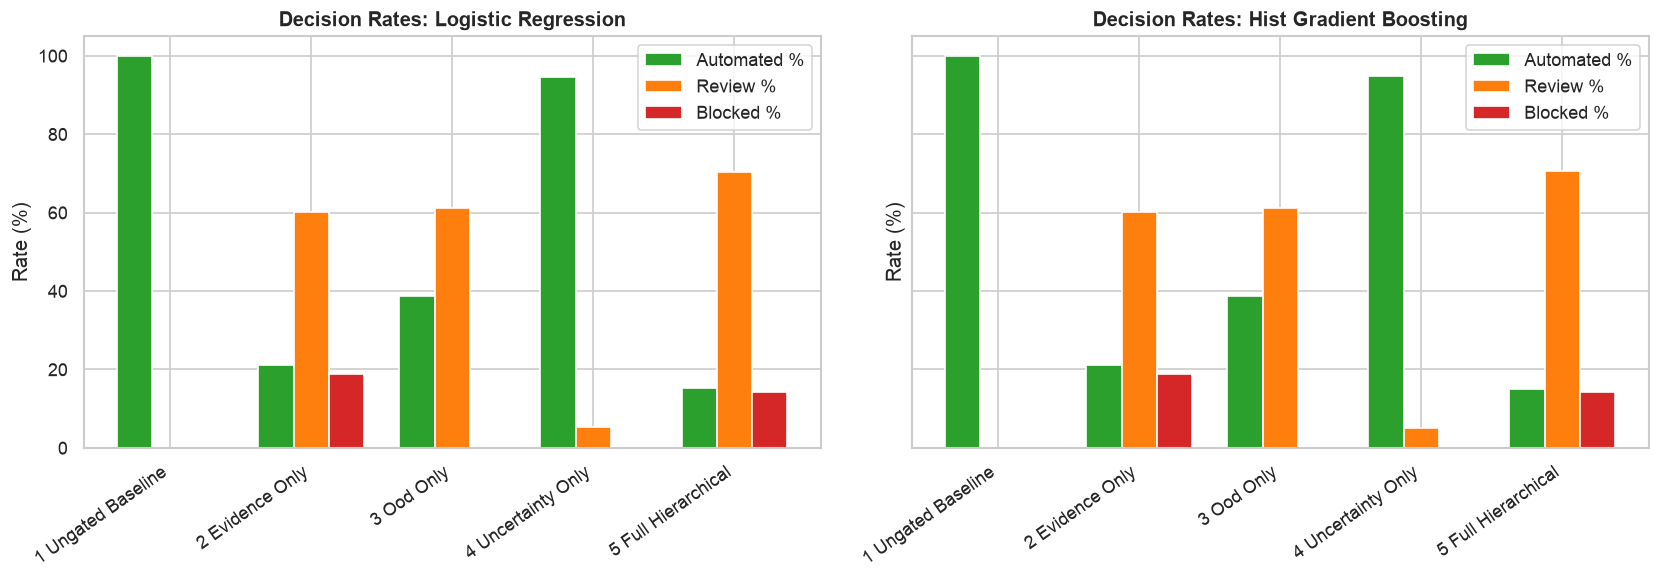

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, mf in zip(axes, ("logistic_regression", "hist_gradient_boosting")):
    mf_df = comparison_df[comparison_df["model_family"] == mf].copy()
    exp_labels = [name.replace("_", " ").title() for name in mf_df["experiment_name"]]
    
    x = np.arange(len(exp_labels))
    width = 0.25
    
    ax.bar(x - width, mf_df["automation_coverage"] * 100, width, label="Automated %", color="#2ca02c")
    ax.bar(x, mf_df["review_rate"] * 100, width, label="Review %", color="#ff7f0e")
    ax.bar(x + width, mf_df["block_rate"] * 100, width, label="Blocked %", color="#d62728")
    
    ax.set_title(f"Decision Rates: {mf.replace('_', ' ').title()}", fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(exp_labels, rotation=35, ha="right")
    ax.set_ylabel("Rate (%)")
    ax.set_ylim(0, 105)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4. Safety Impact: Unsafe Automated Decisions and False Escalation

A primary safety metric is mitigating unsafe automated predictions (especially automated decisions where true financial stress was missed). We also inspect false escalations (unnecessary review for solvent applicants).

       experiment_name  ... false_escalation_rate
0   1_ungated_baseline  ...              0.000000
1   1_ungated_baseline  ...              0.000000
2      2_evidence_only  ...              0.473433
3      2_evidence_only  ...              0.461937
4           3_ood_only  ...              0.353867
5           3_ood_only  ...              0.347133
6   4_uncertainty_only  ...              0.014667
7   4_uncertainty_only  ...              0.016000
8  5_full_hierarchical  ...              0.501998
9  5_full_hierarchical  ...              0.491714

[10 rows x 7 columns]


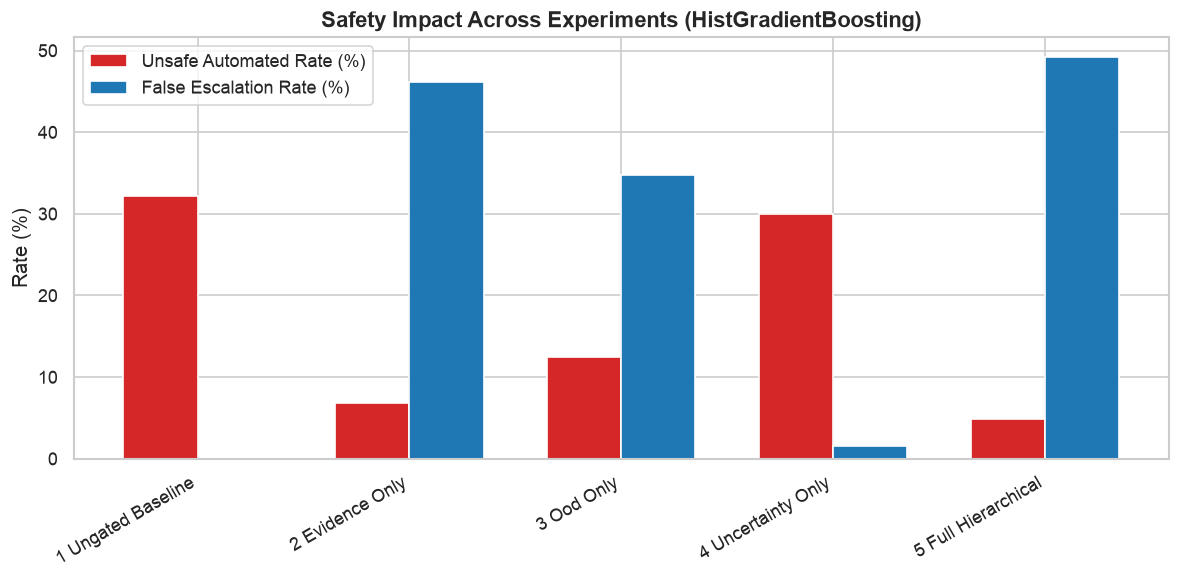

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5))

df_plot = comparison_df[comparison_df["model_family"] == "hist_gradient_boosting"].copy()
labels = [e.replace("_", " ").title() for e in df_plot["experiment_name"]]
x = np.arange(len(labels))
width = 0.35

rects1 = ax1.bar(x - width/2, df_plot["unsafe_automated_rate"] * 100, width, label="Unsafe Automated Rate (%)", color="#d62728")
rects2 = ax1.bar(x + width/2, df_plot["false_escalation_rate"] * 100, width, label="False Escalation Rate (%)", color="#1f77b4")

ax1.set_title("Safety Impact Across Experiments (HistGradientBoosting)", fontsize=13, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=30, ha="right")
ax1.set_ylabel("Rate (%)")
ax1.legend()
plt.tight_layout()
plt.show()

display(comparison_df[["experiment_name", "model_family", "unsafe_automated_count", "unsafe_automated_rate", "unsafe_automated_missed_stress_count", "false_escalation_count", "false_escalation_rate"]])

## 5. Reason Codes Distribution

We inspect the frequency of individual reason codes across the full hierarchical gate decisions.

                                    Frequency
OOD_SHRINKAGE_MAHALANOBIS_HIGH          46032
EVIDENCE_PARTIALLY_UNVERIFIED           11512
EVIDENCE_MISSING_MONTH                  11456
EVIDENCE_MISSING_REQUIRED_FIELD         11456
EVIDENCE_STALE_OBSERVATION              11368
EVIDENCE_CONSISTENCY_CONTRADICTION      10728
UNCERTAINTY_LOGISTIC_VARIANCE_HIGH       2028
UNCERTAINTY_HGB_VARIANCE_HIGH            1932


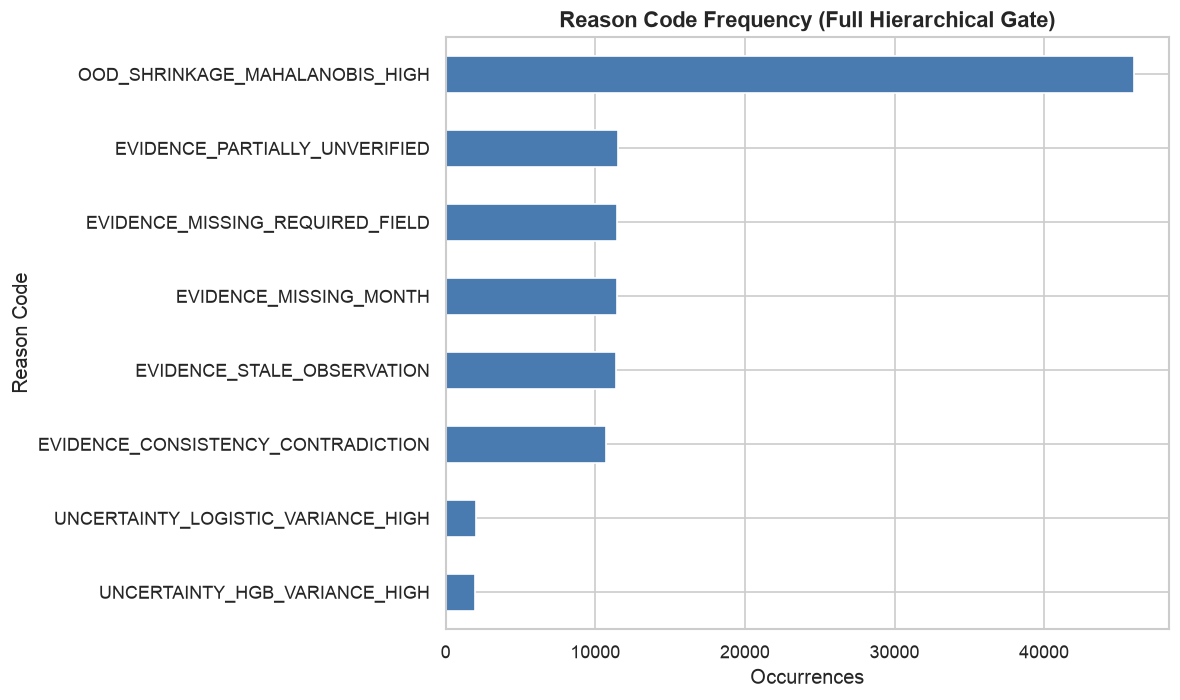

In [6]:
full_reasons = {}
for r in results:
    if r["experiment_name"] == "5_full_hierarchical":
        for code, count in r["reason_code_distribution"].items():
            full_reasons[code] = full_reasons.get(code, 0) + count

reasons_series = pd.Series(full_reasons).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
reasons_series.plot(kind="barh", color="#4a7bb0")
plt.title("Reason Code Frequency (Full Hierarchical Gate)", fontsize=13, fontweight="bold")
plt.xlabel("Occurrences")
plt.ylabel("Reason Code")
plt.tight_layout()
plt.show()

display(reasons_series.sort_values(ascending=False).to_frame("Frequency"))

## 6. Risk-Coverage Pareto Curves Across OOD Thresholds

By sweeping the Shrinkage Mahalanobis OOD threshold, we analyze the operational frontier between automation coverage and unsafe automation risk.

          model_family  ...  unsafe_automated_coverage_rate
0  logistic_regression  ...                        0.000000
1  logistic_regression  ...                        0.142857
2  logistic_regression  ...                        0.289474
3  logistic_regression  ...                        0.292453
4  logistic_regression  ...                        0.255591
5  logistic_regression  ...                        0.255994
6  logistic_regression  ...                        0.273622
7  logistic_regression  ...                        0.296189
8  logistic_regression  ...                        0.299047
9  logistic_regression  ...                        0.304178

[10 rows x 11 columns]


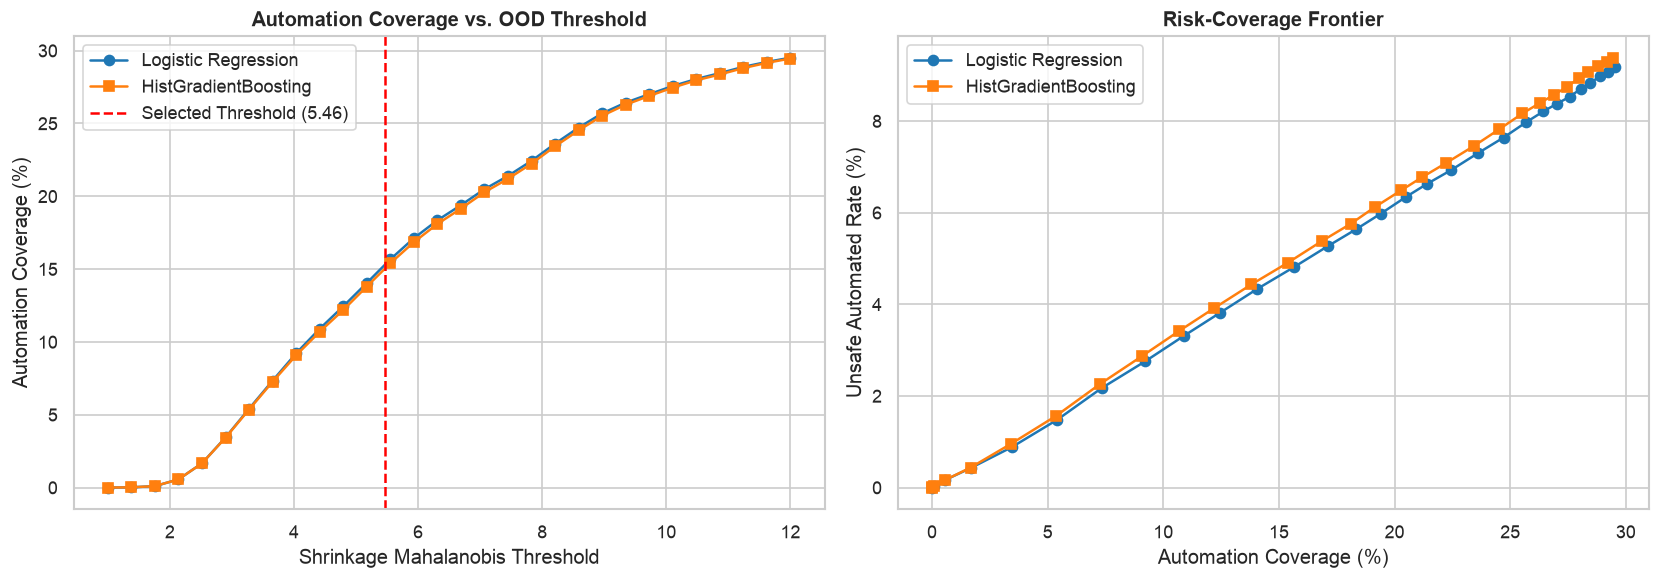

In [7]:
curve_lr = compute_risk_coverage_curve(panel, model_family="logistic_regression")
curve_hgb = compute_risk_coverage_curve(panel, model_family="hist_gradient_boosting")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: OOD Threshold vs Automation Coverage
ax1.plot(curve_lr["ood_threshold"], curve_lr["automation_coverage"] * 100, label="Logistic Regression", marker="o", color="#1f77b4")
ax1.plot(curve_hgb["ood_threshold"], curve_hgb["automation_coverage"] * 100, label="HistGradientBoosting", marker="s", color="#ff7f0e")
ax1.axvline(OOD_THRESHOLD, color="red", linestyle="--", label=f"Selected Threshold ({OOD_THRESHOLD:.2f})")
ax1.set_title("Automation Coverage vs. OOD Threshold", fontsize=12, fontweight="bold")
ax1.set_xlabel("Shrinkage Mahalanobis Threshold")
ax1.set_ylabel("Automation Coverage (%)")
ax1.legend()

# Plot 2: Coverage vs Unsafe Automation Rate (Risk-Coverage Frontier)
ax2.plot(curve_lr["automation_coverage"] * 100, curve_lr["unsafe_automated_rate"] * 100, label="Logistic Regression", marker="o", color="#1f77b4")
ax2.plot(curve_hgb["automation_coverage"] * 100, curve_hgb["unsafe_automated_rate"] * 100, label="HistGradientBoosting", marker="s", color="#ff7f0e")
ax2.set_title("Risk-Coverage Frontier", fontsize=12, fontweight="bold")
ax2.set_xlabel("Automation Coverage (%)")
ax2.set_ylabel("Unsafe Automated Rate (%)")
ax2.legend()

plt.tight_layout()
plt.show()

curves_combined = pd.concat([curve_lr, curve_hgb], ignore_index=True)
display(curves_combined.head(10))

## 7. Persist Artifacts and Audit Metadata

We persist all experiment evaluation tables, risk-coverage curves, reason code counts, and audit metadata into `experiments/safety_gate/`.

In [8]:
# 1. Comparison table
comparison_df.to_csv(OUTPUT_DIR / "experiment_metrics.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "gate_comparison.csv", index=False)

# 2. Risk coverage curves
curves_combined.to_csv(OUTPUT_DIR / "risk_coverage_curve.csv", index=False)

# 3. Reason codes distribution
reasons_df = reasons_series.sort_values(ascending=False).reset_index()
reasons_df.columns = ["reason_code", "count"]
reasons_df.to_csv(OUTPUT_DIR / "reason_codes_distribution.csv", index=False)

# 4. Gate summary metadata
summary_metadata = {
    "gate_version": GATE_VERSION,
    "ood_threshold": OOD_THRESHOLD,
    "uncertainty_thresholds": UNCERTAINTY_THRESHOLDS,
    "total_panel_rows": len(panel),
    "experiments_evaluated": list(comparison_df["experiment_name"].unique()),
    "models_evaluated": list(comparison_df["model_family"].unique()),
    "clean_test_coverage": {
        r["model_family"]: float(r["automation_coverage"])
        for r in results if r["experiment_name"] == "1_ungated_baseline"
    },
    "full_gate_coverage": {
        r["model_family"]: float(r["automation_coverage"])
        for r in results if r["experiment_name"] == "5_full_hierarchical"
    },
    "full_gate_unsafe_rate": {
        r["model_family"]: float(r["unsafe_automated_rate"])
        for r in results if r["experiment_name"] == "5_full_hierarchical"
    },
    "full_gate_block_rate": {
        r["model_family"]: float(r["block_rate"])
        for r in results if r["experiment_name"] == "5_full_hierarchical"
    },
}

with open(OUTPUT_DIR / "gate_summary.json", "w") as f:
    json.dump(summary_metadata, f, indent=2)

# 5. Persist sample of full decisions for auditability
g5.head(5000).to_csv(OUTPUT_DIR / "gate_decisions_sample.csv", index=False)

print("Artifacts successfully persisted to:", OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob("*")):
    size_kb = p.stat().st_size / 1024
    print(f" - {p.name} ({size_kb:.1f} KB)")

Artifacts successfully persisted to: /Users/gauravkumarsingh/Documents/capstone project/experiments/safety_gate
 - experiment_metrics.csv (1.7 KB)
 - gate_comparison.csv (1.7 KB)
 - gate_decisions_sample.csv (1438.4 KB)
 - gate_summary.json (1.0 KB)
 - reason_codes_distribution.csv (0.3 KB)
 - risk_coverage_curve.csv (9.3 KB)
